# Assignment 4 Python Exploratory Data Analysis

This notebook uses the Comparable Stores and Candidate Markets data provided for Assignment 4. The exploratory analysis focuses on annual transactions and the market characteristics that may help explain variation in transactions.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

sns.set_theme(style="whitegrid")

stores = pd.read_excel("FRO_Assignment4_EDA.xlsx", sheet_name="Comparable Stores", skiprows=2)
candidates = pd.read_excel("FRO_Assignment4_EDA.xlsx", sheet_name="Candidate Markets", skiprows=2)

stores.head()

,StoreID,StoreName,MarketType,StoreFormat,Population5mi,MedianHouseholdIncome,Competitors5mi,StoreSqFt,AnnualTransactions,AvgTransactionValue,AnnualSales
0,FRO001,Boulder,Urban,Standard,130000,82500,4,16000,14000,90.0,1260000.0
1,FRO002,Fort Collins,Suburban,Compact,100000,82500,11,10000,13800,84.0,1159200.0
2,FRO003,Colorado Springs,Small City,Standard,145000,112500,8,19000,12900,80.0,1032000.0
3,FRO004,Arvada,Urban,Compact,170000,115000,7,11000,14200,85.0,1207000.0
4,FRO005,Lakewood,Suburban,Standard,162500,90000,3,18000,13500,83.0,1120500.0


## Analysis 1: Distribution of annual transactions

A histogram with a kernel density estimate shows the overall distribution of annual transactions across comparable stores.

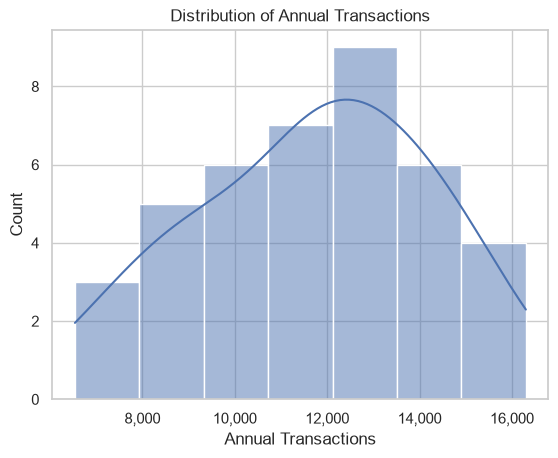

In [2]:
ax = sns.histplot(data=stores, x="AnnualTransactions", kde=True)
ax.set_title("Distribution of Annual Transactions")
ax.set_xlabel("Annual Transactions")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

**Insight:** Annual transactions are concentrated around the middle of the observed range, with no obvious extreme outliers. This provides a reasonable baseline for comparing the candidate-market forecasts.

## Analysis 2: Annual transactions by store format

A box plot with overlaid observations compares the transaction distributions for Compact and Standard stores.

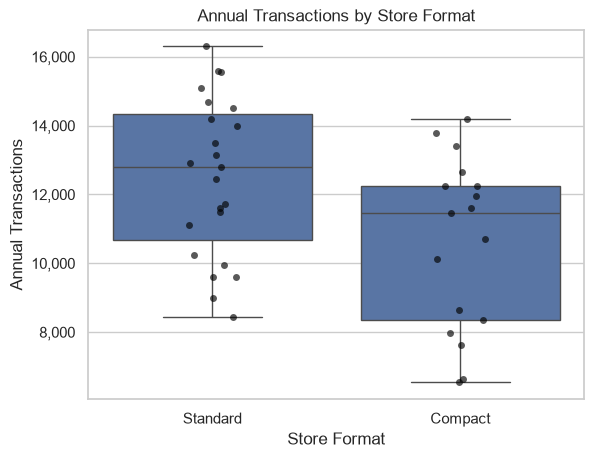

In [3]:
ax = sns.boxplot(data=stores, x="StoreFormat", y="AnnualTransactions")
sns.stripplot(data=stores, x="StoreFormat", y="AnnualTransactions", color="black", alpha=0.65)
ax.set_title("Annual Transactions by Store Format")
ax.set_xlabel("Store Format")
ax.set_ylabel("Annual Transactions")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

**Insight:** Standard and Compact stores have overlapping transaction ranges, so store format alone does not fully distinguish expected annual transactions in the comparable-store sample.

## Analysis 3: Pairwise relationships among market characteristics

A pair plot shows the distributions and pairwise relationships for population, competition, store size, and annual transactions, colored by market type.

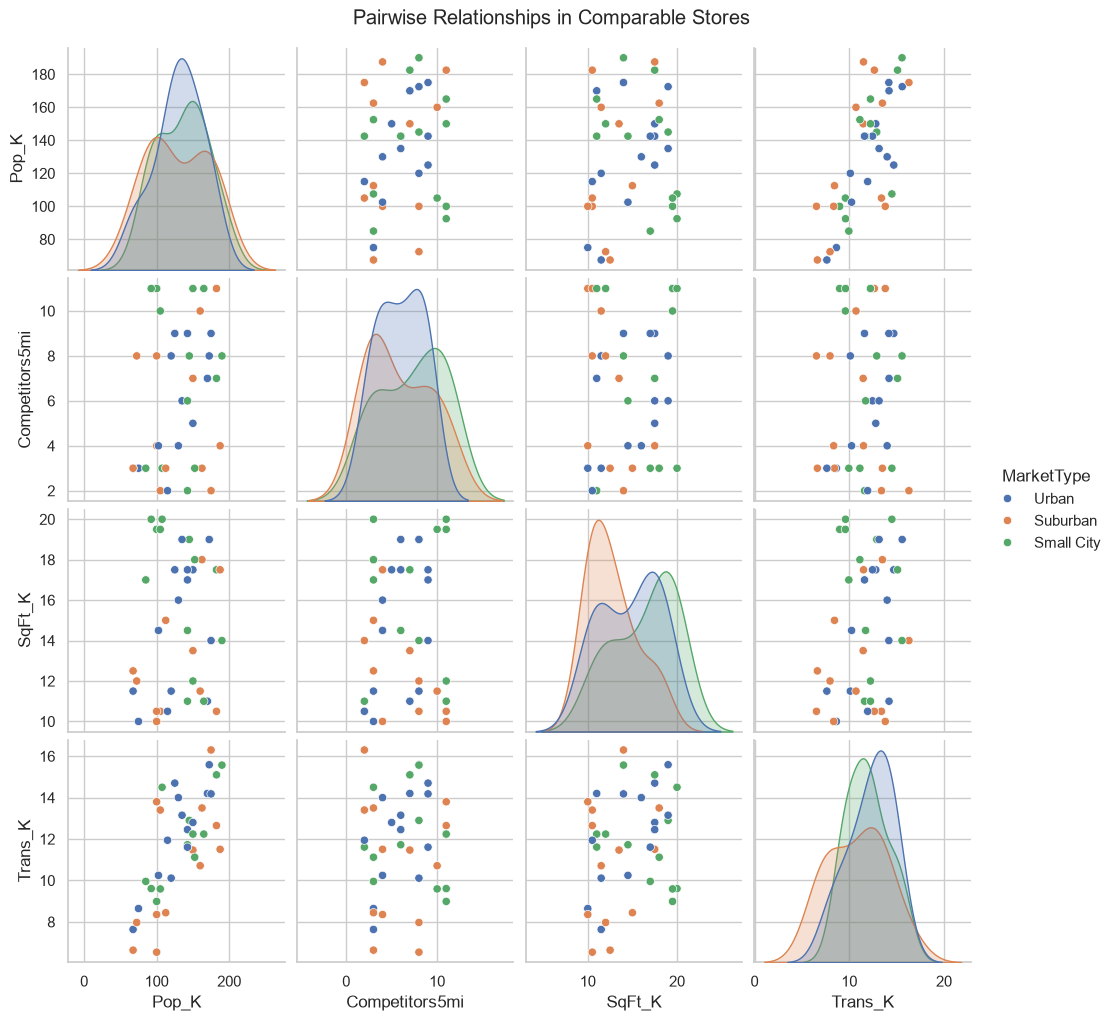

In [4]:
pair_data = stores.assign(
    Pop_K=stores["Population5mi"] / 1000,
    SqFt_K=stores["StoreSqFt"] / 1000,
    Trans_K=stores["AnnualTransactions"] / 1000
)
g = sns.pairplot(
    data=pair_data,
    hue="MarketType",
    vars=["Pop_K", "Competitors5mi", "SqFt_K", "Trans_K"]
)
g.figure.suptitle("Pairwise Relationships in Comparable Stores", y=1.02)
plt.show()

**Insight:** The pair plot suggests that population is the clearest positive visual relationship with annual transactions. The market-type colors overlap, so the relationship is not limited to one market classification.

## Analysis 4: Comparable stores by market type

A count plot checks whether the comparable-store sample is balanced across market types.

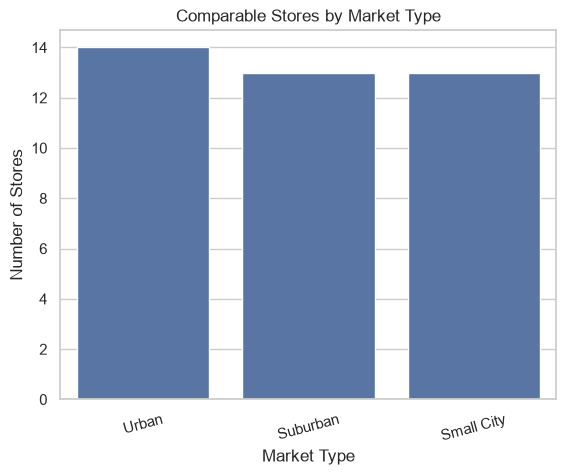

In [5]:
ax = sns.countplot(data=stores, x="MarketType")
ax.set_title("Comparable Stores by Market Type")
ax.set_xlabel("Market Type")
ax.set_ylabel("Number of Stores")
plt.xticks(rotation=15)
plt.show()

**Insight:** The market-type groups are represented in the comparable-store sample, but the group sizes should still be considered when comparing patterns because each category contains relatively few observations.

## Analysis 5: Correlation among numeric variables

A correlation heat map summarizes the linear associations among the numeric market variables and annual transactions.

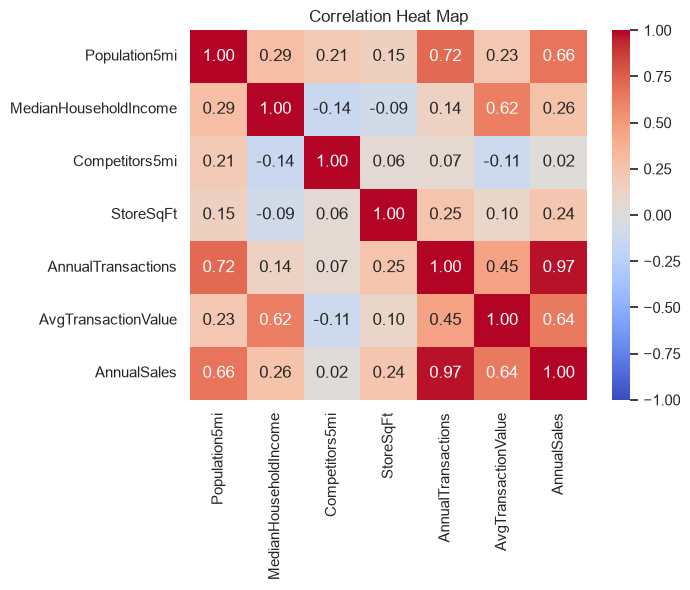

In [6]:
corr = stores.corr(numeric_only=True)
ax = sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Correlation Heat Map")
plt.show()

**Insight:** Population within five miles has the strongest positive correlation with annual transactions in the comparable-store data. Annual sales is calculated from transactions, so it is not an appropriate independent predictor.

## Analysis 6: Population and annual transactions

A scatter plot, colored by market type, evaluates the relationship between five-mile population and annual transactions.

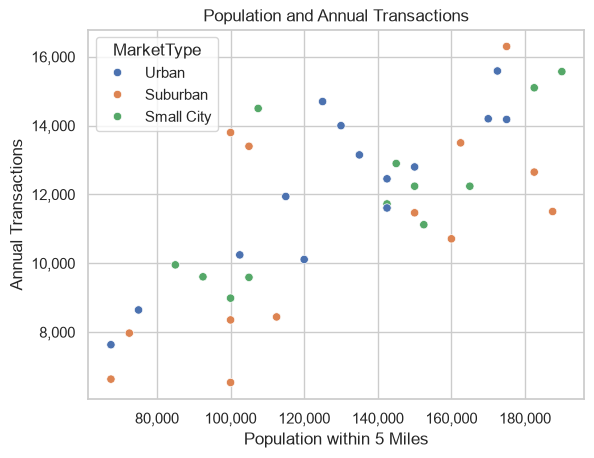

In [7]:
ax = sns.scatterplot(
    data=stores,
    x="Population5mi",
    y="AnnualTransactions",
    hue="MarketType"
)
ax.set_title("Population and Annual Transactions")
ax.set_xlabel("Population within 5 Miles")
ax.set_ylabel("Annual Transactions")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

**Insight:** Stores in more highly populated five-mile markets generally have more annual transactions. The pattern appears across market types, supporting population as a useful candidate predictor.

## Analysis 7: Competition and annual transactions

A regression plot tests whether the number of nearby competitors is linearly associated with annual transactions.

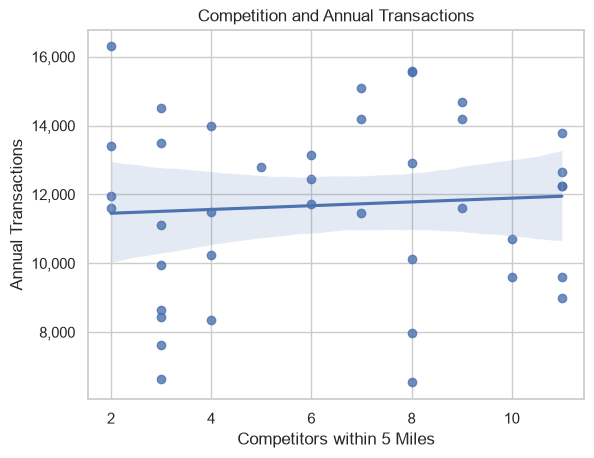

In [8]:
ax = sns.regplot(data=stores, x="Competitors5mi", y="AnnualTransactions")
ax.set_title("Competition and Annual Transactions")
ax.set_xlabel("Competitors within 5 Miles")
ax.set_ylabel("Annual Transactions")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

**Insight:** The fitted line is relatively flat, indicating little linear association between nearby competitors and annual transactions in this sample. Competition alone is therefore a weak simple-regression predictor.

## Analysis 8: Median household income and annual transactions

A regression plot tests whether median household income is linearly associated with annual transactions.

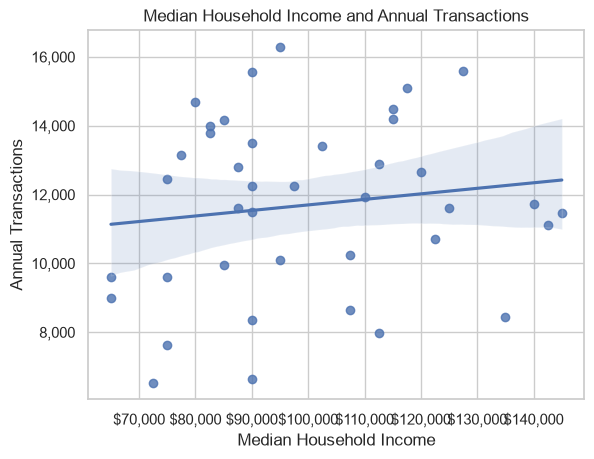

In [9]:
ax = sns.regplot(data=stores, x="MedianHouseholdIncome", y="AnnualTransactions")
ax.set_title("Median Household Income and Annual Transactions")
ax.set_xlabel("Median Household Income")
ax.set_ylabel("Annual Transactions")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

**Insight:** Income has a weaker and less consistent relationship with annual transactions than population. Income should be interpreted cautiously because it may be related to other market characteristics.

## Analysis 9: Population regression model

A regression plot evaluates population as the selected simple-regression predictor for annual transactions.

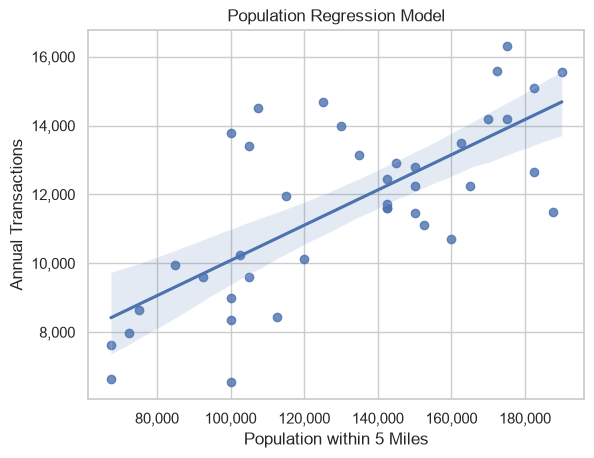

In [10]:
ax = sns.regplot(data=stores, x="Population5mi", y="AnnualTransactions")
ax.set_title("Population Regression Model")
ax.set_xlabel("Population within 5 Miles")
ax.set_ylabel("Annual Transactions")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

**Insight:** Population is the strongest single predictor among the variables reviewed because it has the clearest positive trend and the strongest correlation with annual transactions. Forecasts should remain within the population range represented by the comparable stores.

## Analysis 10: Population regression by store format

A grouped regression plot compares the population-to-transactions relationship for Compact and Standard stores.

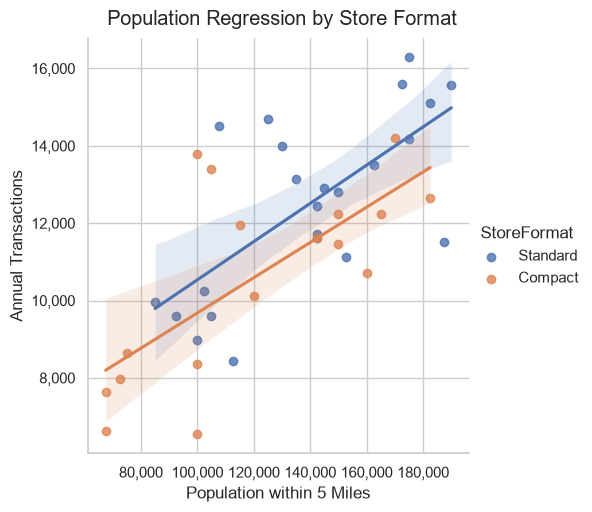

In [11]:
g = sns.lmplot(
    data=stores,
    x="Population5mi",
    y="AnnualTransactions",
    hue="StoreFormat"
)
g.set_axis_labels("Population within 5 Miles", "Annual Transactions")
g.figure.suptitle("Population Regression by Store Format", y=1.02)
for ax in g.axes.flat:
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.show()

**Insight:** Both store formats show a positive population-to-transactions relationship, although their fitted lines may differ. Store format should therefore be considered when applying a population-based forecast to the Standard and Compact candidate markets.

## Management limitations

These plots show association, not causation. The comparable-store sample is limited, and regression forecasts are most reliable within the observed ranges of the data. Annual sales is derived from annual transactions and should not be used as an independent predictor. The EDA should support, rather than replace, the Excel regression analysis and the investment decision.